In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Loading the data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def heart_data():
  csv_path = '/content/drive/MyDrive/dataset_heart.csv'
  df = pd.read_csv(csv_path)
  return df
# 1 Male 0 Female --> sex
# 1 not sick 2 sick --> heart disease
heart = heart_data()
heart.head()

,age,sex,chest pain type,resting blood pressure,serum cholestoral,fasting blood sugar,resting electrocardiographic results,max heart rate,exercise induced angina,oldpeak,ST segment,major vessels,thal,heart disease
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,2
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,1
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,2
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,1
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,1


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

heart.columns = ['age', 'sex', 'chest pain type', 'resting blood pressure', 'serum cholestoral',
              'fasting blood sugar', 'resting electrocardiographic results', 'maximum heart rate achieved ', 'exang',
              'oldpeak', 'slope', 'ca', 'thal', 'target']

# Remplacer les valeurs de target pour la légende
heart['target'] = heart['target'].map({1: 'Absence', 2: 'Presence'})


In [ ]:
heart.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 270 entries, 0 to 269
Data columns (total 14 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   age                                   270 non-null    int64  
 1   sex                                   270 non-null    int64  
 2   chest pain type                       270 non-null    int64  
 3   resting blood pressure                270 non-null    int64  
 4   serum cholestoral                     270 non-null    int64  
 5   fasting blood sugar                   270 non-null    int64  
 6   resting electrocardiographic results  270 non-null    int64  
 7   maximum heart rate achieved           270 non-null    int64  
 8   exang                                 270 non-null    int64  
 9   oldpeak                               270 non-null    float64
 10  slope                                 270 non-null    int64  
 11  ca                 

In [ ]:
print(heart.columns.tolist())

['age', 'sex', 'chest pain type', 'resting blood pressure', 'serum cholestoral', 'fasting blood sugar', 'resting electrocardiographic results', 'maximum heart rate achieved ', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


Scatterplot for outcomes for every value

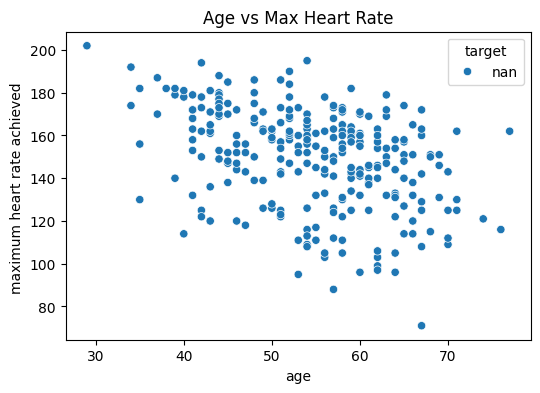

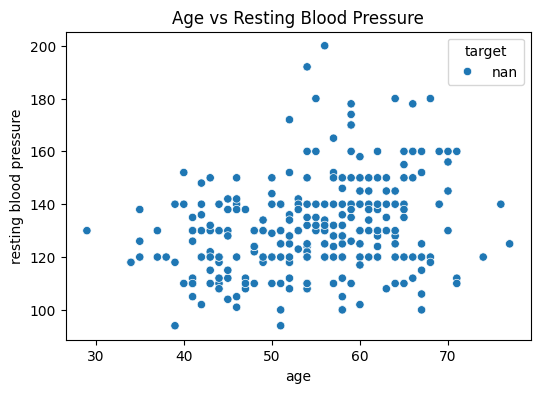

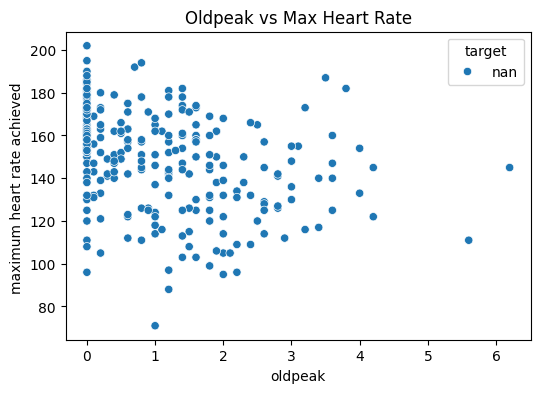

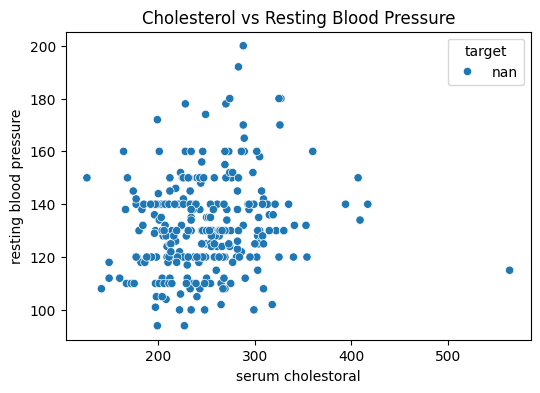

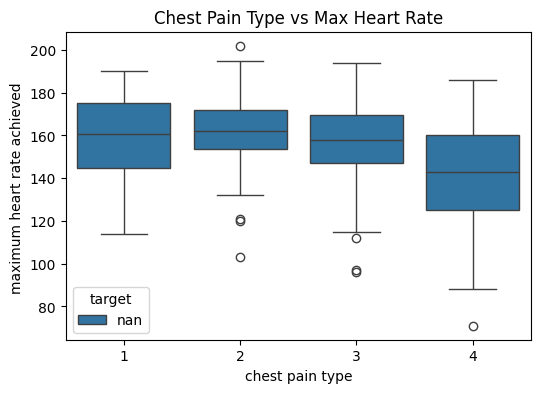

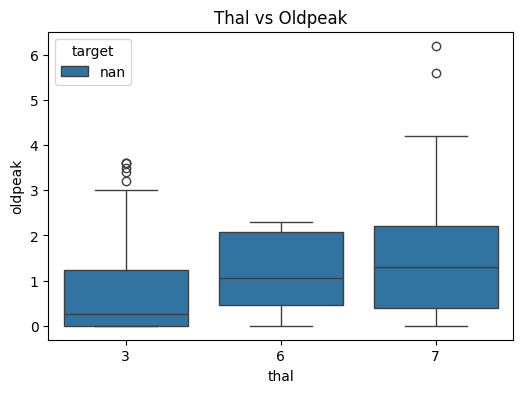

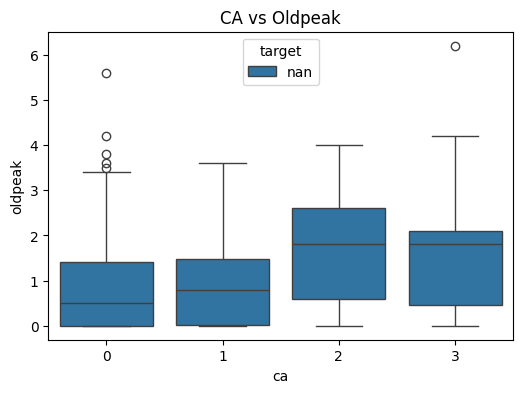

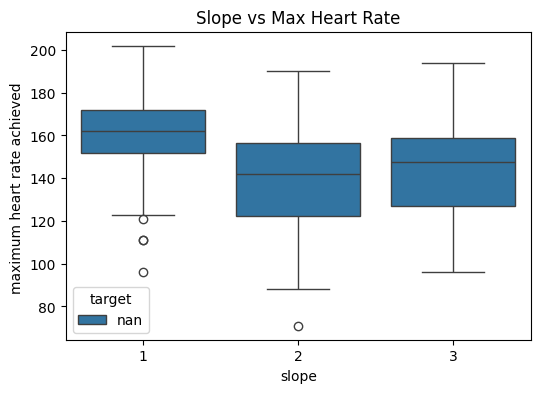

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

heart['target'] = heart['target'].astype(str)

# ── CONTINUOUS VARIABLES ──────────────────────────────────────────
# Paires choisies par corrélation (heatmap) + logique médicale

# 1. Age vs Max Heart Rate (corrélation -0.40 avec target)
plt.figure(figsize=(6,4))
sns.scatterplot(data=heart, x='age', y='maximum heart rate achieved ', hue='target')
plt.title('Age vs Max Heart Rate')
plt.show()

# 2. Age vs Resting Blood Pressure (liés médicalement)
plt.figure(figsize=(6,4))
sns.scatterplot(data=heart, x='age', y='resting blood pressure', hue='target')
plt.title('Age vs Resting Blood Pressure')
plt.show()

# 3. Oldpeak vs Max Heart Rate (corrélation forte avec target)
plt.figure(figsize=(6,4))
sns.scatterplot(data=heart, x='oldpeak', y='maximum heart rate achieved ', hue='target')
plt.title('Oldpeak vs Max Heart Rate')
plt.show()

# 4. Serum Cholestoral vs Resting Blood Pressure (liés médicalement)
plt.figure(figsize=(6,4))
sns.scatterplot(data=heart, x='serum cholestoral', y='resting blood pressure', hue='target')
plt.title('Cholesterol vs Resting Blood Pressure')
plt.show()


# ── CATEGORICAL VARIABLES ─────────────────────────────────────────
# Boxplots — montrent la distribution par catégorie vs target

# 5. Chest Pain Type vs Max Heart Rate (corrélation 0.42 avec target)
plt.figure(figsize=(6,4))
sns.boxplot(data=heart, x='chest pain type', y='maximum heart rate achieved ', hue='target')
plt.title('Chest Pain Type vs Max Heart Rate')
plt.show()

# 6. Thal vs Oldpeak (thal = 0.53 avec target, meilleure corrélation)
plt.figure(figsize=(6,4))
sns.boxplot(data=heart, x='thal', y='oldpeak', hue='target')
plt.title('Thal vs Oldpeak')
plt.show()

# 7. CA vs Oldpeak (ca = 0.46 avec target)
plt.figure(figsize=(6,4))
sns.boxplot(data=heart, x='ca', y='oldpeak', hue='target')
plt.title('CA vs Oldpeak')
plt.show()

# 8. Slope vs Max Heart Rate (logique médicale)
plt.figure(figsize=(6,4))
sns.boxplot(data=heart, x='slope', y='maximum heart rate achieved ', hue='target')
plt.title('Slope vs Max Heart Rate')
plt.show()

In [ ]:
heart.describe()

,age,sex,chest pain type,resting blood pressure,serum cholestoral,fasting blood sugar,resting electrocardiographic results,maximum heart rate achieved,exang,oldpeak,slope,ca,thal
count,270.000000,270.000000,270.000000,270.000000,270.000000,270.000000,270.000000,270.000000,270.000000,270.00000,270.000000,270.000000,270.000000
mean,54.433333,0.677778,3.174074,131.344444,249.659259,0.148148,1.022222,149.677778,0.329630,1.05000,1.585185,0.670370,4.696296
std,9.109067,0.468195,0.950090,17.861608,51.686237,0.355906,0.997891,23.165717,0.470952,1.14521,0.614390,0.943896,1.940659
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.00000,1.000000,0.000000,3.000000
25%,48.000000,0.000000,3.000000,120.000000,213.000000,0.000000,0.000000,133.000000,0.000000,0.00000,1.000000,0.000000,3.000000
50%,55.000000,1.000000,3.000000,130.000000,245.000000,0.000000,2.000000,153.500000,0.000000,0.80000,2.000000,0.000000,3.000000
75%,61.000000,1.000000,4.000000,140.000000,280.000000,0.000000,2.000000,166.000000,1.000000,1.60000,2.000000,1.000000,7.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.20000,3.000000,3.000000,7.000000


<function matplotlib.pyplot.show(close=None, block=None)>

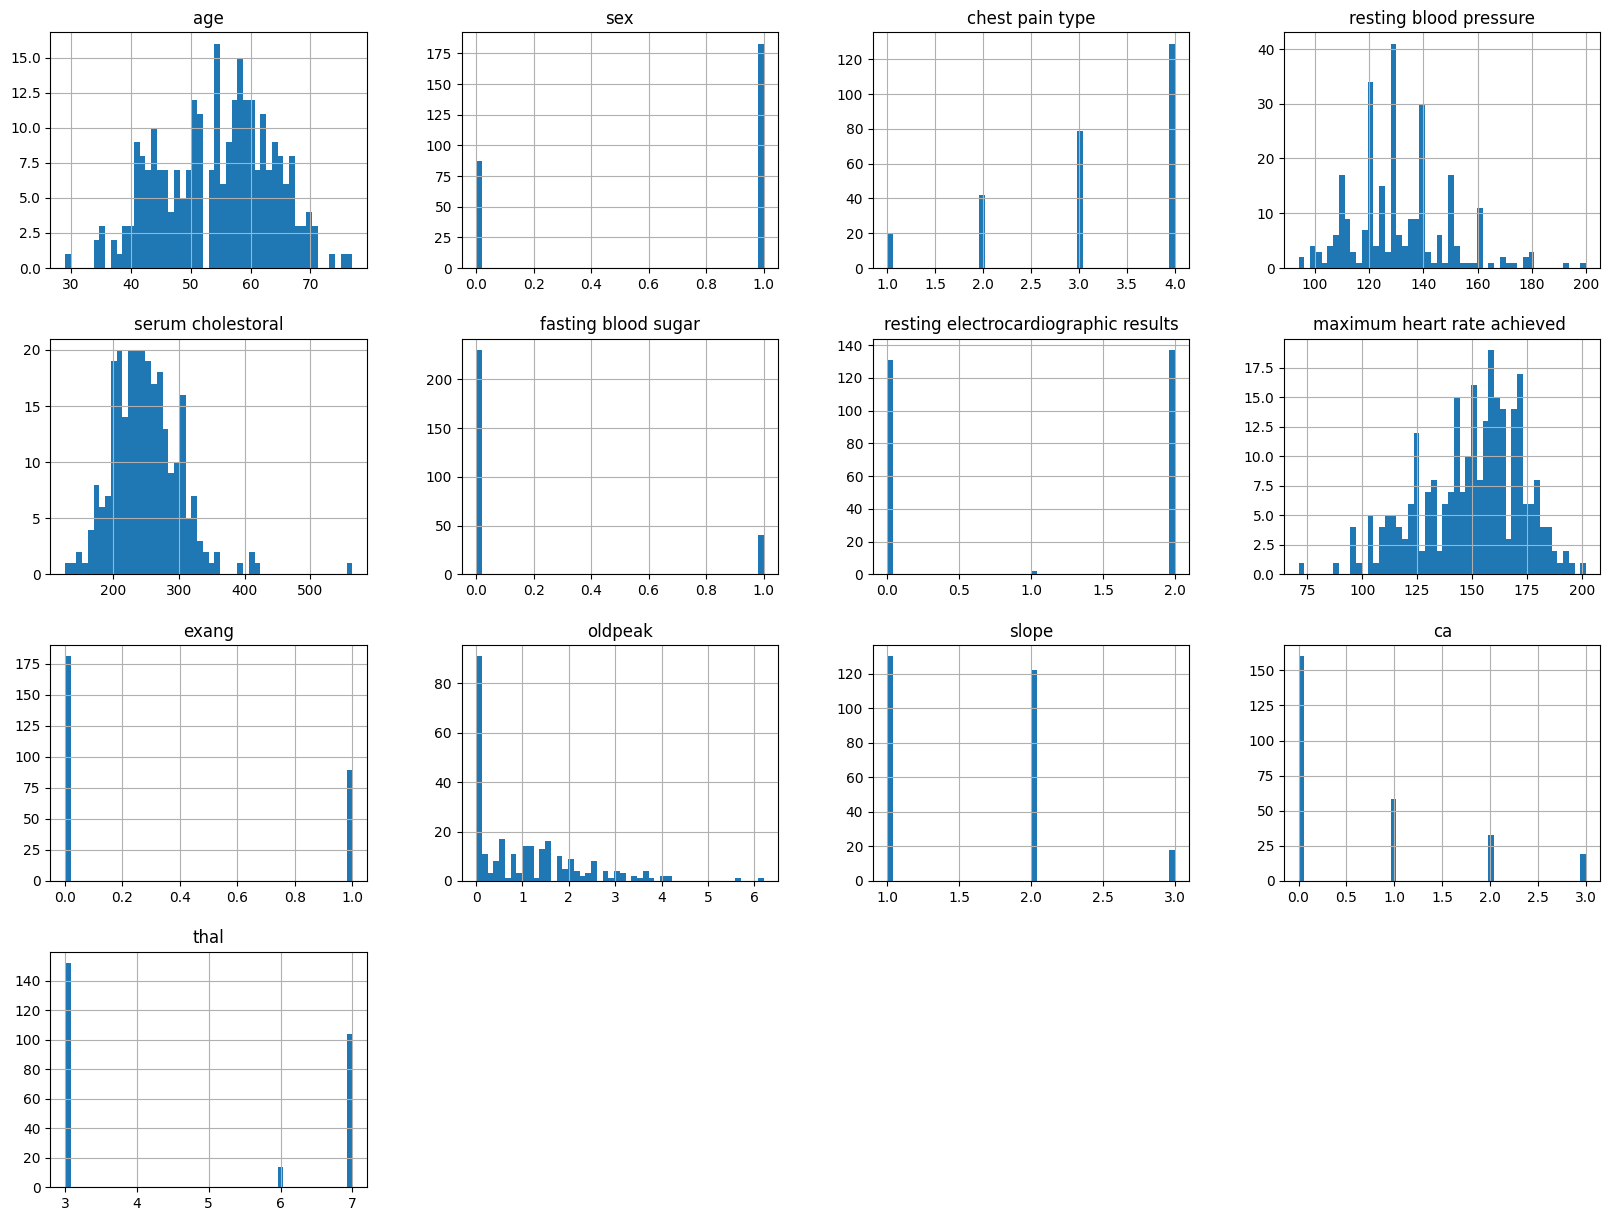

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
heart.hist(bins=50, figsize=(20, 15)) # the histogramm to see our numeriques variable
plt.show

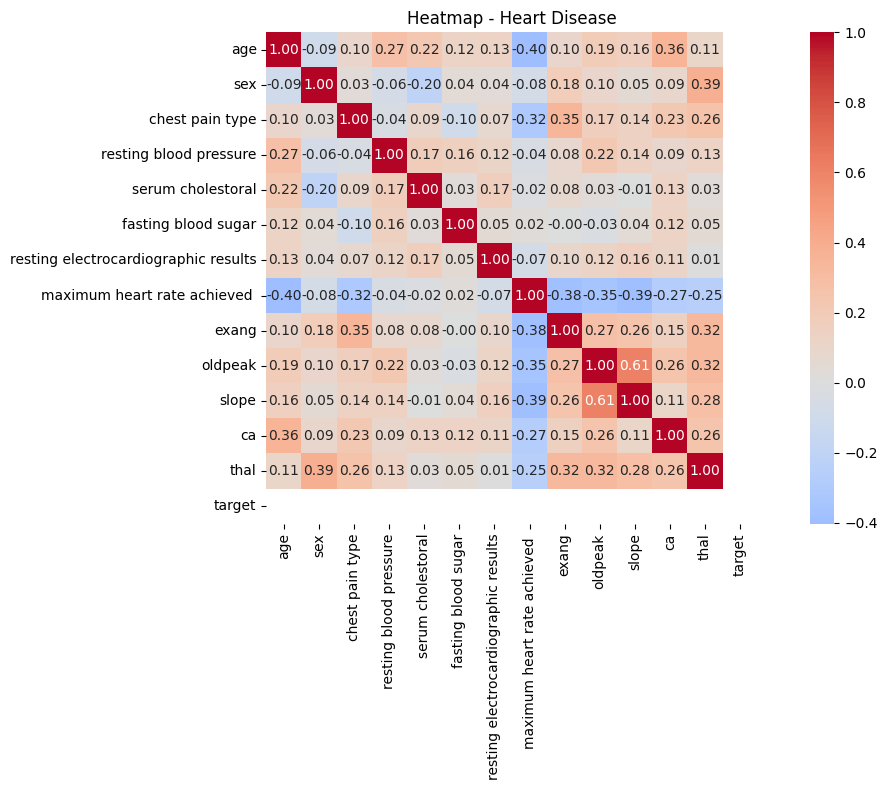

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))
correlation_matrix = heart.corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    square=True
)
plt.title('Heatmap - Heart Disease')
plt.tight_layout()
plt.show()

Creating arrays

In [ ]:
import pandas as pd
import numpy as np

def heart_data():
  csv_path = '/content/drive/MyDrive/dataset_heart.csv'
  df = pd.read_csv(csv_path)
  return df

heart = heart_data() # Reloads the original dataframe with 'heart disease' column

# Rename 'heart disease' to 'target' to be consistent with previous renaming and subsequent usage
heart.rename(columns={'heart disease': 'target'}, inplace=True)

X = heart.drop('target', axis=1).values
y = heart['target'].values

Creating the test and training set

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

(216, 13)
(54, 13)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler

# Normalised
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


model = LogisticRegression(
    max_iter=1000,
    random_state=42,
    solver='lbfgs'
)


model.fit(X_train, y_train)


y_pred = model.predict(X_test)


print("Accuracy :", accuracy_score(y_test, y_pred))
print("\nClassification Report :")
print(classification_report(y_test, y_pred))
print("\nConfusion Matrix :")
print(confusion_matrix(y_test, y_pred))

Accuracy : 0.9074074074074074

Classification Report :
              precision    recall  f1-score   support

           1       0.91      0.94      0.93        33
           2       0.90      0.86      0.88        21

    accuracy                           0.91        54
   macro avg       0.91      0.90      0.90        54
weighted avg       0.91      0.91      0.91        54


Confusion Matrix :
[[31  2]
 [ 3 18]]


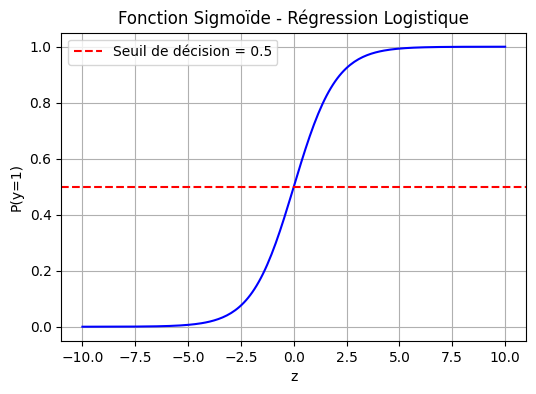

In [ ]:
x = np.linspace(-10, 10, 200)
sigmoid = 1 / (1 + np.exp(-x))

plt.figure(figsize=(6,4))
plt.plot(x, sigmoid, color='blue')
plt.axhline(0.5, color='red', linestyle='--', label='Seuil de décision = 0.5')
plt.xlabel('z')
plt.ylabel('P(y=1)')
plt.title('Fonction Sigmoïde - Régression Logistique')
plt.legend()
plt.grid(True)
plt.show()

Is the model working ?

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Accuracy
print("Accuracy Train :", accuracy_score(y_train, model.predict(X_train)))
print("Accuracy Test  :", accuracy_score(y_test, y_pred))

Accuracy Train : 0.8379629629629629
Accuracy Test  : 0.9074074074074074


Train < test so it's a good model

creation de clusters


In [ ]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3)
heart['cluster'] = kmeans.fit_predict(X)
print(heart['cluster'].value_counts())

cluster
1    121
0     90
2     59
Name: count, dtype: int64


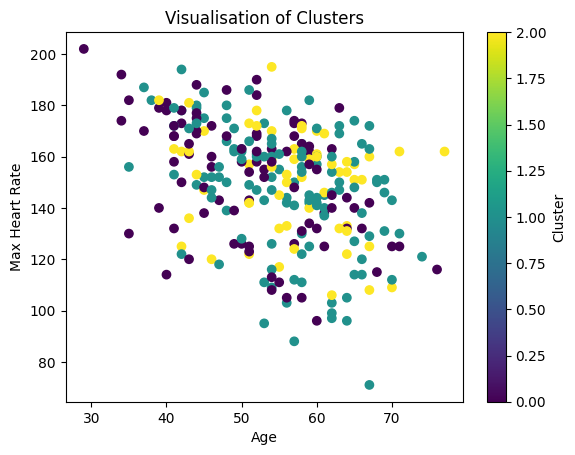

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(heart['age'], heart['max heart rate'], c=heart['cluster'], cmap='viridis')
plt.xlabel('Age')
plt.ylabel('Max Heart Rate')
plt.colorbar(label='Cluster')
plt.title('Visualisation of Clusters')
plt.show()

Cluster are mixed, we can't really seraparate them. Maybe ut's because age vs max heart rate are not the best features to visualize. So I used the heatmap to see that the most correlated are thal vs major vessels, chest pain vs max heart rate and old peak vs angina. Lets visualize them

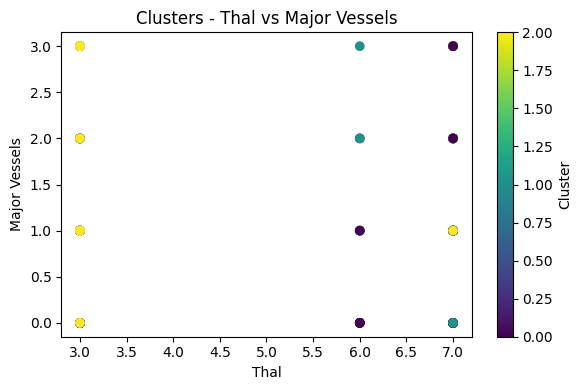

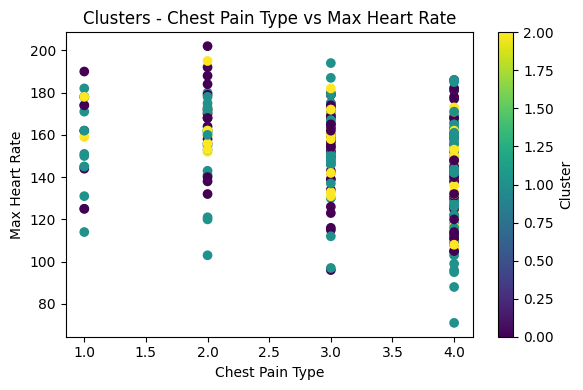

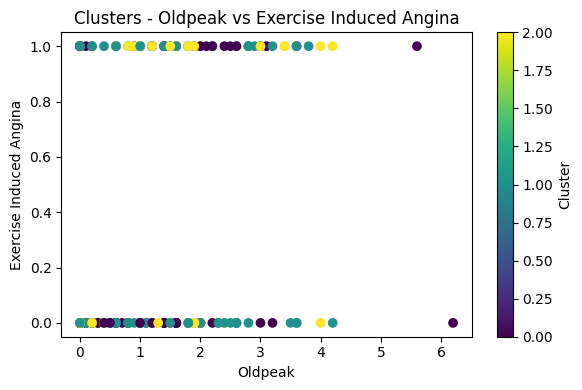

In [ ]:
# --- Scatterplot 1 : thal vs major vessels ---
plt.figure(figsize=(6, 4))
plt.scatter(heart['thal'], heart['major vessels'], c=heart['cluster'], cmap='viridis')
plt.xlabel('Thal')
plt.ylabel('Major Vessels')
plt.colorbar(label='Cluster')
plt.title('Clusters - Thal vs Major Vessels')
plt.tight_layout()
plt.show()

# --- Scatterplot 2 : chest pain type vs max heart rate ---
plt.figure(figsize=(6, 4))
plt.scatter(heart['chest pain type'], heart['max heart rate'], c=heart['cluster'], cmap='viridis')
plt.xlabel('Chest Pain Type')
plt.ylabel('Max Heart Rate')
plt.colorbar(label='Cluster')
plt.title('Clusters - Chest Pain Type vs Max Heart Rate')
plt.tight_layout()
plt.show()

# --- Scatterplot 3 : oldpeak vs exercise induced angina ---
plt.figure(figsize=(6, 4))
plt.scatter(heart['oldpeak'], heart['exercise induced angina'], c=heart['cluster'], cmap='viridis')
plt.xlabel('Oldpeak')
plt.ylabel('Exercise Induced Angina')
plt.colorbar(label='Cluster')
plt.title('Clusters - Oldpeak vs Exercise Induced Angina')
plt.tight_layout()
plt.show()

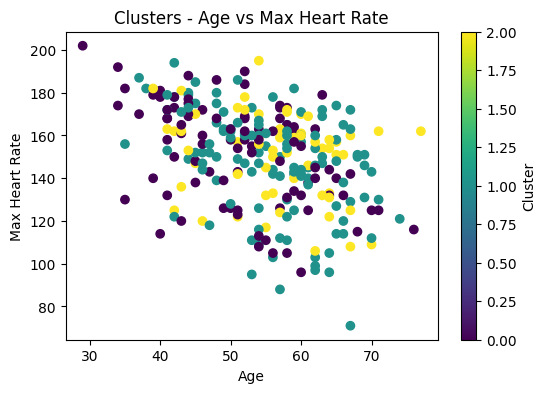

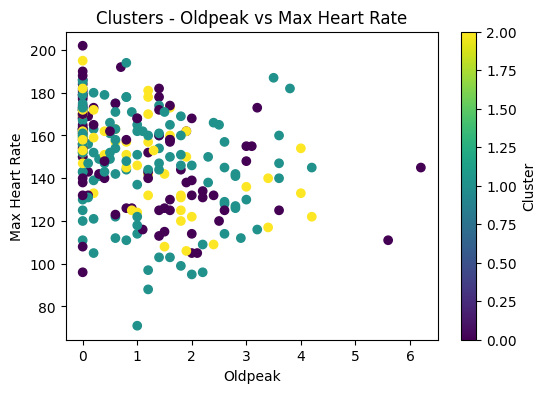

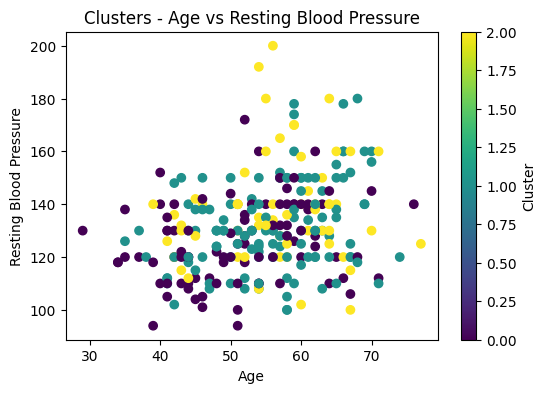

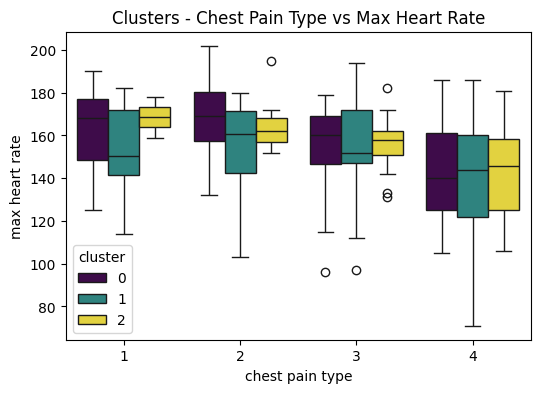

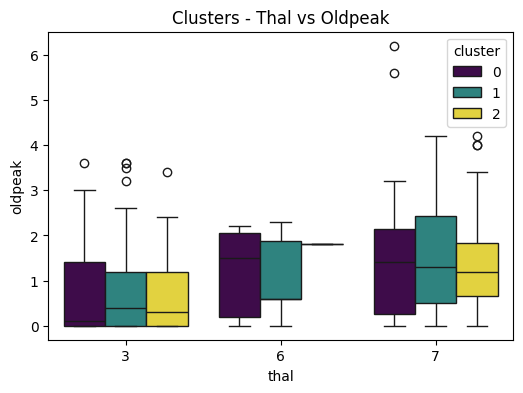

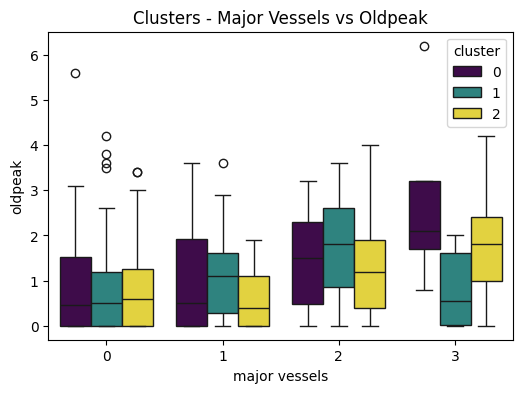

In [ ]:
# ── CONTINUOUS VARIABLES ─────────────────────────────────────────

# 1. Age vs Max Heart Rate
plt.figure(figsize=(6,4))
plt.scatter(heart['age'], heart['max heart rate'], c=heart['cluster'], cmap='viridis')
plt.xlabel('Age')
plt.ylabel('Max Heart Rate')
plt.colorbar(label='Cluster')
plt.title('Clusters - Age vs Max Heart Rate')
plt.show()

# 2. Oldpeak vs Max Heart Rate
plt.figure(figsize=(6,4))
plt.scatter(heart['oldpeak'], heart['max heart rate'], c=heart['cluster'], cmap='viridis')
plt.xlabel('Oldpeak')
plt.ylabel('Max Heart Rate')
plt.colorbar(label='Cluster')
plt.title('Clusters - Oldpeak vs Max Heart Rate')
plt.show()

# 3. Age vs Resting Blood Pressure
plt.figure(figsize=(6,4))
plt.scatter(heart['age'], heart['resting blood pressure'], c=heart['cluster'], cmap='viridis')
plt.xlabel('Age')
plt.ylabel('Resting Blood Pressure')
plt.colorbar(label='Cluster')
plt.title('Clusters - Age vs Resting Blood Pressure')
plt.show()


# ── CATEGORICAL VARIABLES ─────────────────────────────────────────

# 4. Chest Pain Type vs Max Heart Rate
plt.figure(figsize=(6,4))
sns.boxplot(data=heart, x='chest pain type', y='max heart rate', hue='cluster', palette='viridis')
plt.title('Clusters - Chest Pain Type vs Max Heart Rate')
plt.show()

# 5. Thal vs Oldpeak
plt.figure(figsize=(6,4))
sns.boxplot(data=heart, x='thal', y='oldpeak', hue='cluster', palette='viridis')
plt.title('Clusters - Thal vs Oldpeak')
plt.show()

# 6. CA vs Oldpeak
plt.figure(figsize=(6,4))
sns.boxplot(data=heart, x='major vessels', y='oldpeak', hue='cluster', palette='viridis') # Corrected 'ca' to 'major vessels'
plt.title('Clusters - Major Vessels vs Oldpeak')
plt.show()

We want to do the ANN to see if we can improve our accuracy rate

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score


# Step 4 - Arrays
X = heart.drop('target', axis=1)
y = heart['target'].map({1: 0, 2: 1}) # Convert target to 0 and 1 for binary_crossentropy

# Step 5 - Train/Test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Normalisation
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Step 6 - Building ANN
model = Sequential([
    Dense(20, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(20, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Training
model.fit(X_train, y_train, epochs=50, batch_size=16, verbose=1)

# Evaluation
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Accuracy ANN : {accuracy:.2f}")

Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.5046 - loss: 0.7140
Epoch 2/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.6065 - loss: 0.6475
Epoch 3/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6898 - loss: 0.5958
Epoch 4/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7454 - loss: 0.5552
Epoch 5/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.7778 - loss: 0.5173
Epoch 6/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7824 - loss: 0.4854
Epoch 7/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8056 - loss: 0.4586
Epoch 8/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8056 - loss: 0.4336
Epoch 9/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8148 - loss: 0.4136
Epoch 10/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8333 - loss: 0.3973
Epoch 11/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8380 - loss: 0.3841
Epoch 12/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8380 - l

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Variables continues uniquement
continuous_vars = ['age', 'resting blood pressure', 'serum cholestoral',
                   'max heart rate', 'oldpeak'] # Changed 'maximum heart rate achieved ' to 'max heart rate'

# Step 4 - Arrays avec variables continues seulement
X = heart[continuous_vars]
y = heart['target'].map({1: 0, 2: 1})  # Map target values 1 to 0 and 2 to 1 for binary_crossentropy

# Step 5 - Train/Test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Normalisation
symmetric_scaler = StandardScaler()
X_train = symmetric_scaler.fit_transform(X_train)
X_test = symmetric_scaler.transform(X_test)

# Step 6 - Building ANN avec hidden layers 20, 20
model = Sequential([
    Dense(20, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(20, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Training
model.fit(X_train, y_train, epochs=50, batch_size=16, verbose=1)

# Evaluation
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Accuracy ANN (continuous only) : {accuracy:.2f}")

Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


14/14 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.4167 - loss: 0.7356
Epoch 2/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5556 - loss: 0.6893
Epoch 3/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6157 - loss: 0.6588
Epoch 4/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6806 - loss: 0.6370
Epoch 5/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6944 - loss: 0.6168
Epoch 6/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7269 - loss: 0.6019
Epoch 7/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7454 - loss: 0.5884
Epoch 8/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7407 - loss: 0.5767
Epoch 9/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7454 - loss: 0.5686
Epoch 10/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7454 - loss: 0.5605  
Epoch 11/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7546 - loss: 0.5525 
Epoch 12/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7546 - loss: 